In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


In [2]:
dataset_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("16-11-2026", "Task 2", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
display(df[['Age', 'Rating', 'Sentiment_Compound', 'Recommended IND']].head())


Dataset successfully loaded: 23486 rows, 23 columns.


,Age,Rating,Sentiment_Compound,Recommended IND
0,33,4,0.8932,1
1,34,5,0.9729,1
2,60,3,0.9427,0
3,50,5,0.7182,1
4,47,5,0.9436,1


In [3]:
num_cols = [
    'Age', 'Rating', 'Sentiment_Compound', 'Sentiment_Pos', 'Sentiment_Neg',
    'Review_Length', 'Review_Word_Count', 'Positive_Word_Count', 'Negative_Word_Count',
    'Fit_Issue_Word_Count', 'Positive Feedback Count', 'Exclamation_Count'
]

dept_dummies = pd.get_dummies(df['Department Name'].fillna('Unknown'), prefix='Dept', drop_first=True)

df['Sentiment_x_Age'] = df['Sentiment_Compound'] * (df['Age'] / 50.0)
df['Rating_x_Length'] = df['Rating'] * np.log1p(df['Review_Length'])
df['Pos_to_Neg_Ratio'] = (df['Positive_Word_Count'] + 1.0) / (df['Negative_Word_Count'] + 1.0)
df['Sentiment_Compound^2'] = df['Sentiment_Compound'] ** 2
df['Rating^2'] = df['Rating'] ** 2
derived_cols = ['Sentiment_x_Age', 'Rating_x_Length', 'Pos_to_Neg_Ratio', 'Sentiment_Compound^2', 'Rating^2']

np.random.seed(42)
n_samples = len(df)
df['Noise_Random_Uniform'] = np.random.uniform(-1, 1, n_samples)
df['Noise_Random_Gaussian'] = np.random.normal(0, 1, n_samples)
df['Noise_Permuted_Age'] = np.random.permutation(df['Age'].values)
df['Noise_High_Freq_Modulo'] = (df['Clothing ID'] % 13) / 13.0
df['Noise_Spurious_Index'] = np.random.choice([0, 1], size=n_samples, p=[0.7, 0.3])
noise_cols = ['Noise_Random_Uniform', 'Noise_Random_Gaussian', 'Noise_Permuted_Age', 'Noise_High_Freq_Modulo', 'Noise_Spurious_Index']

feature_columns = num_cols + derived_cols + noise_cols + list(dept_dummies.columns)
X_raw = pd.concat([df[num_cols + derived_cols + noise_cols], dept_dummies], axis=1).fillna(0).values
y = df['Recommended IND'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.20, stratify=y, random_state=42)
print(f"Feature matrix assembled: {X_scaled.shape[1]} features across {X_scaled.shape[0]} records.")


Feature matrix assembled: 27 features across 23486 records.


In [4]:
lc_csv = "learning_curve_sample_size_evaluations.csv"
if not os.path.exists(lc_csv):
    lc_csv = os.path.join("16-11-2026", "Task 2", "learning_curve_sample_size_evaluations.csv")

df_lc_table = pd.read_csv(lc_csv)
print("Empirical Learning Curve Evaluations Across Progressive Training Cohort Sizes:")
display(df_lc_table)


Empirical Learning Curve Evaluations Across Progressive Training Cohort Sizes:


,Sample_Fraction_Pct,Effective_Train_Samples,Unreg_Train_Acc,Unreg_Val_Acc,Unreg_Gap,Reg_Train_Acc,Reg_Val_Acc,Reg_Gap
0,10,1503,1.0,0.9178,0.0822,0.9602,0.9380,0.0222
1,32,4884,1.0,0.9158,0.0842,0.9534,0.9375,0.0159
2,55,8266,1.0,0.9188,0.0812,0.9493,0.9377,0.0116
3,77,11648,1.0,0.9177,0.0823,0.9471,0.9398,0.0073
4,100,15030,1.0,0.9171,0.0829,0.9470,0.9405,0.0064


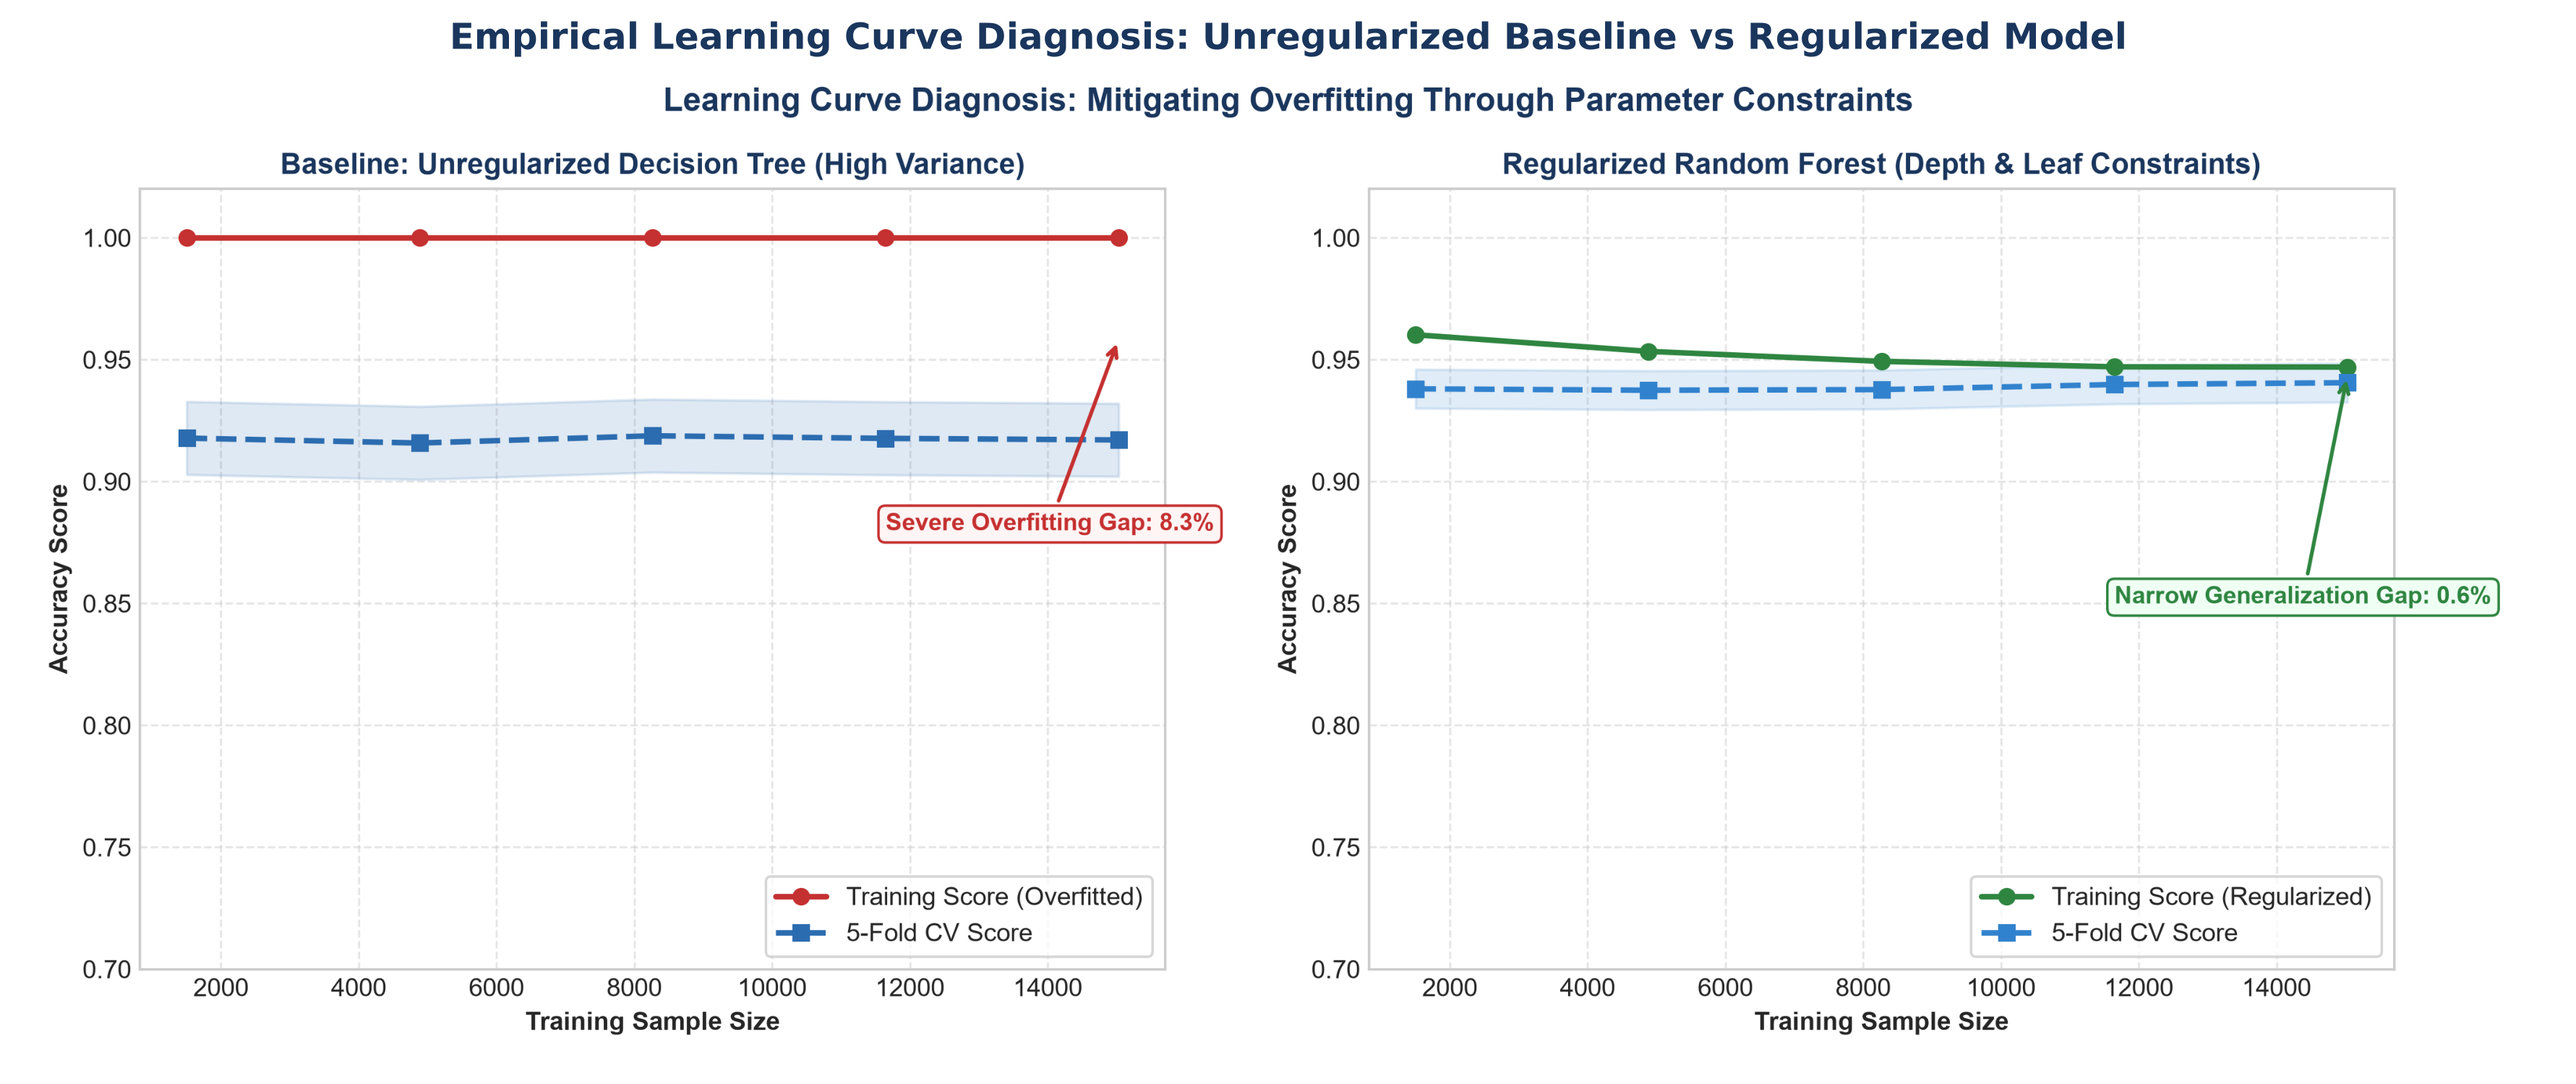

In [5]:
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
lc_img_path = "overfitting_learning_curves_diagnosis.png"
if not os.path.exists(lc_img_path):
    lc_img_path = os.path.join("16-11-2026", "Task 2", "overfitting_learning_curves_diagnosis.png")

img_lc = mpimg.imread(lc_img_path)
ax.imshow(img_lc)
ax.axis('off')
ax.set_title("Empirical Learning Curve Diagnosis: Unregularized Baseline vs Regularized Model", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()


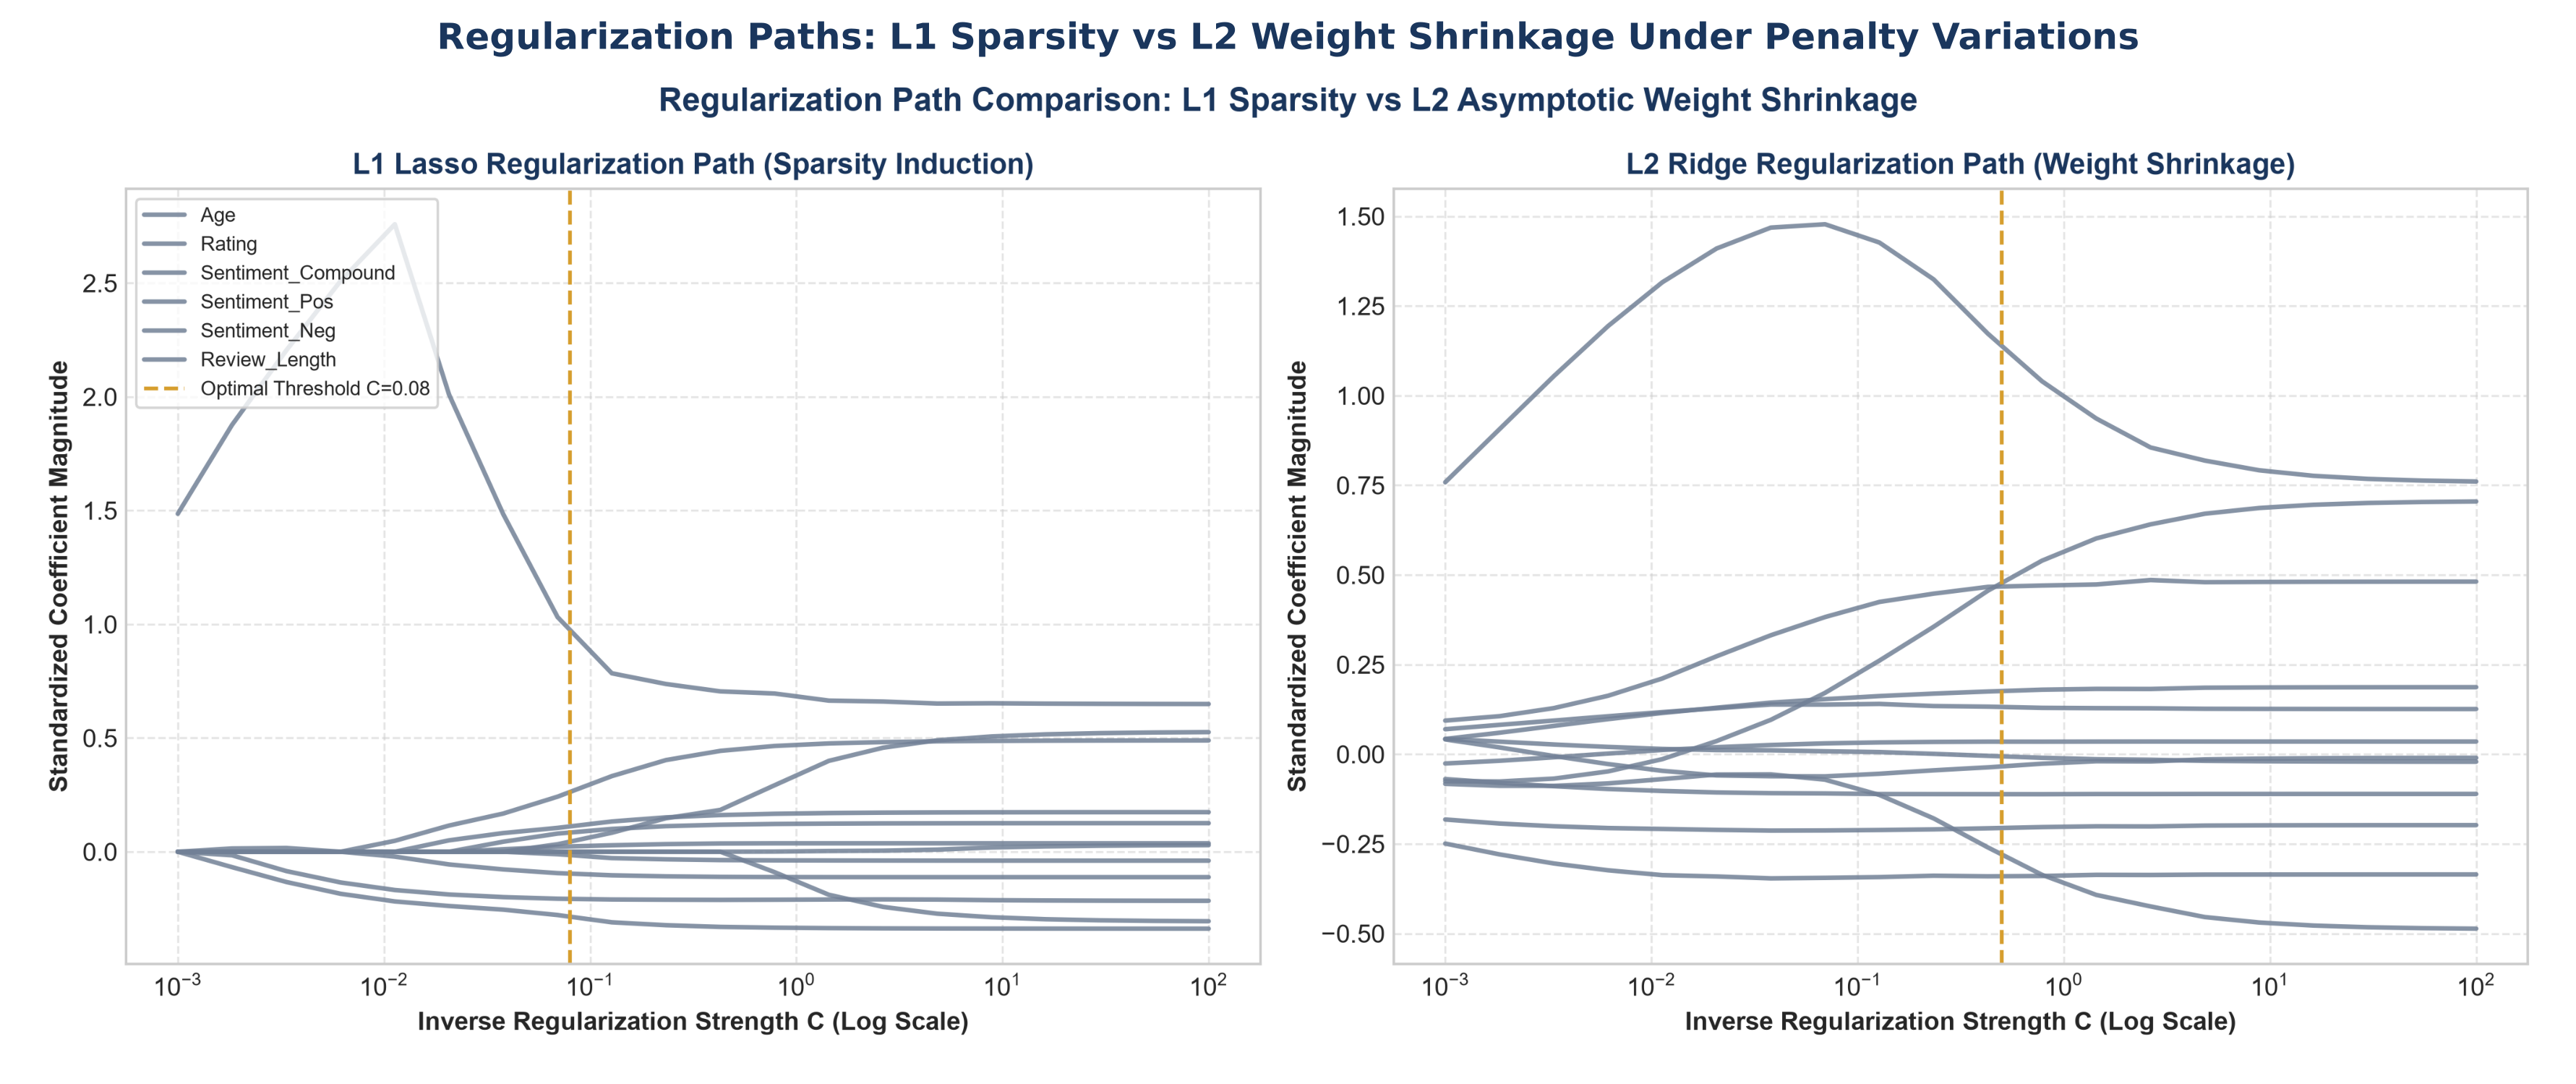

In [6]:
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
path_img = "regularization_penalty_path_l1_l2.png"
if not os.path.exists(path_img):
    path_img = os.path.join("16-11-2026", "Task 2", "regularization_penalty_path_l1_l2.png")

img_path = mpimg.imread(path_img)
ax.imshow(img_path)
ax.axis('off')
ax.set_title("Regularization Paths: L1 Sparsity vs L2 Weight Shrinkage Under Penalty Variations", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()


In [7]:
fs_csv = "feature_selection_elimination_summary.csv"
if not os.path.exists(fs_csv):
    fs_csv = os.path.join("16-11-2026", "Task 2", "feature_selection_elimination_summary.csv")

df_fs_table = pd.read_csv(fs_csv)
print("Feature Selection and Sparsity Elimination Summary (L1 Penalization at C=0.08):")
display(df_fs_table.head(15))


Feature Selection and Sparsity Elimination Summary (L1 Penalization at C=0.08):


,Feature_Index,Feature_Name,Feature_Category,L1_Coefficient,Absolute_Weight,Retained_Status,Noise_Properly_Filtered
0,17,Rating^2,Engineered,2.36337,2.36337,Retained,N/A (Signal Feature)
1,2,Rating,Domain Raw,0.95117,0.95117,Retained,N/A (Signal Feature)
2,5,Sentiment_Neg,Domain Raw,-0.28797,0.28797,Retained,N/A (Signal Feature)
3,4,Sentiment_Pos,Domain Raw,0.26531,0.26531,Retained,N/A (Signal Feature)
4,9,Negative_Word_Count,Domain Raw,-0.20763,0.20763,Retained,N/A (Signal Feature)
5,16,Sentiment_Compound^2,Engineered,0.13033,0.13033,Retained,N/A (Signal Feature)
6,1,Age,Domain Raw,0.11276,0.11276,Retained,N/A (Signal Feature)
7,11,Positive Feedback Count,Domain Raw,-0.09687,0.09687,Retained,N/A (Signal Feature)
8,12,Exclamation_Count,Domain Raw,0.08554,0.08554,Retained,N/A (Signal Feature)
9,7,Review_Word_Count,Domain Raw,0.04320,0.04320,Retained,N/A (Signal Feature)


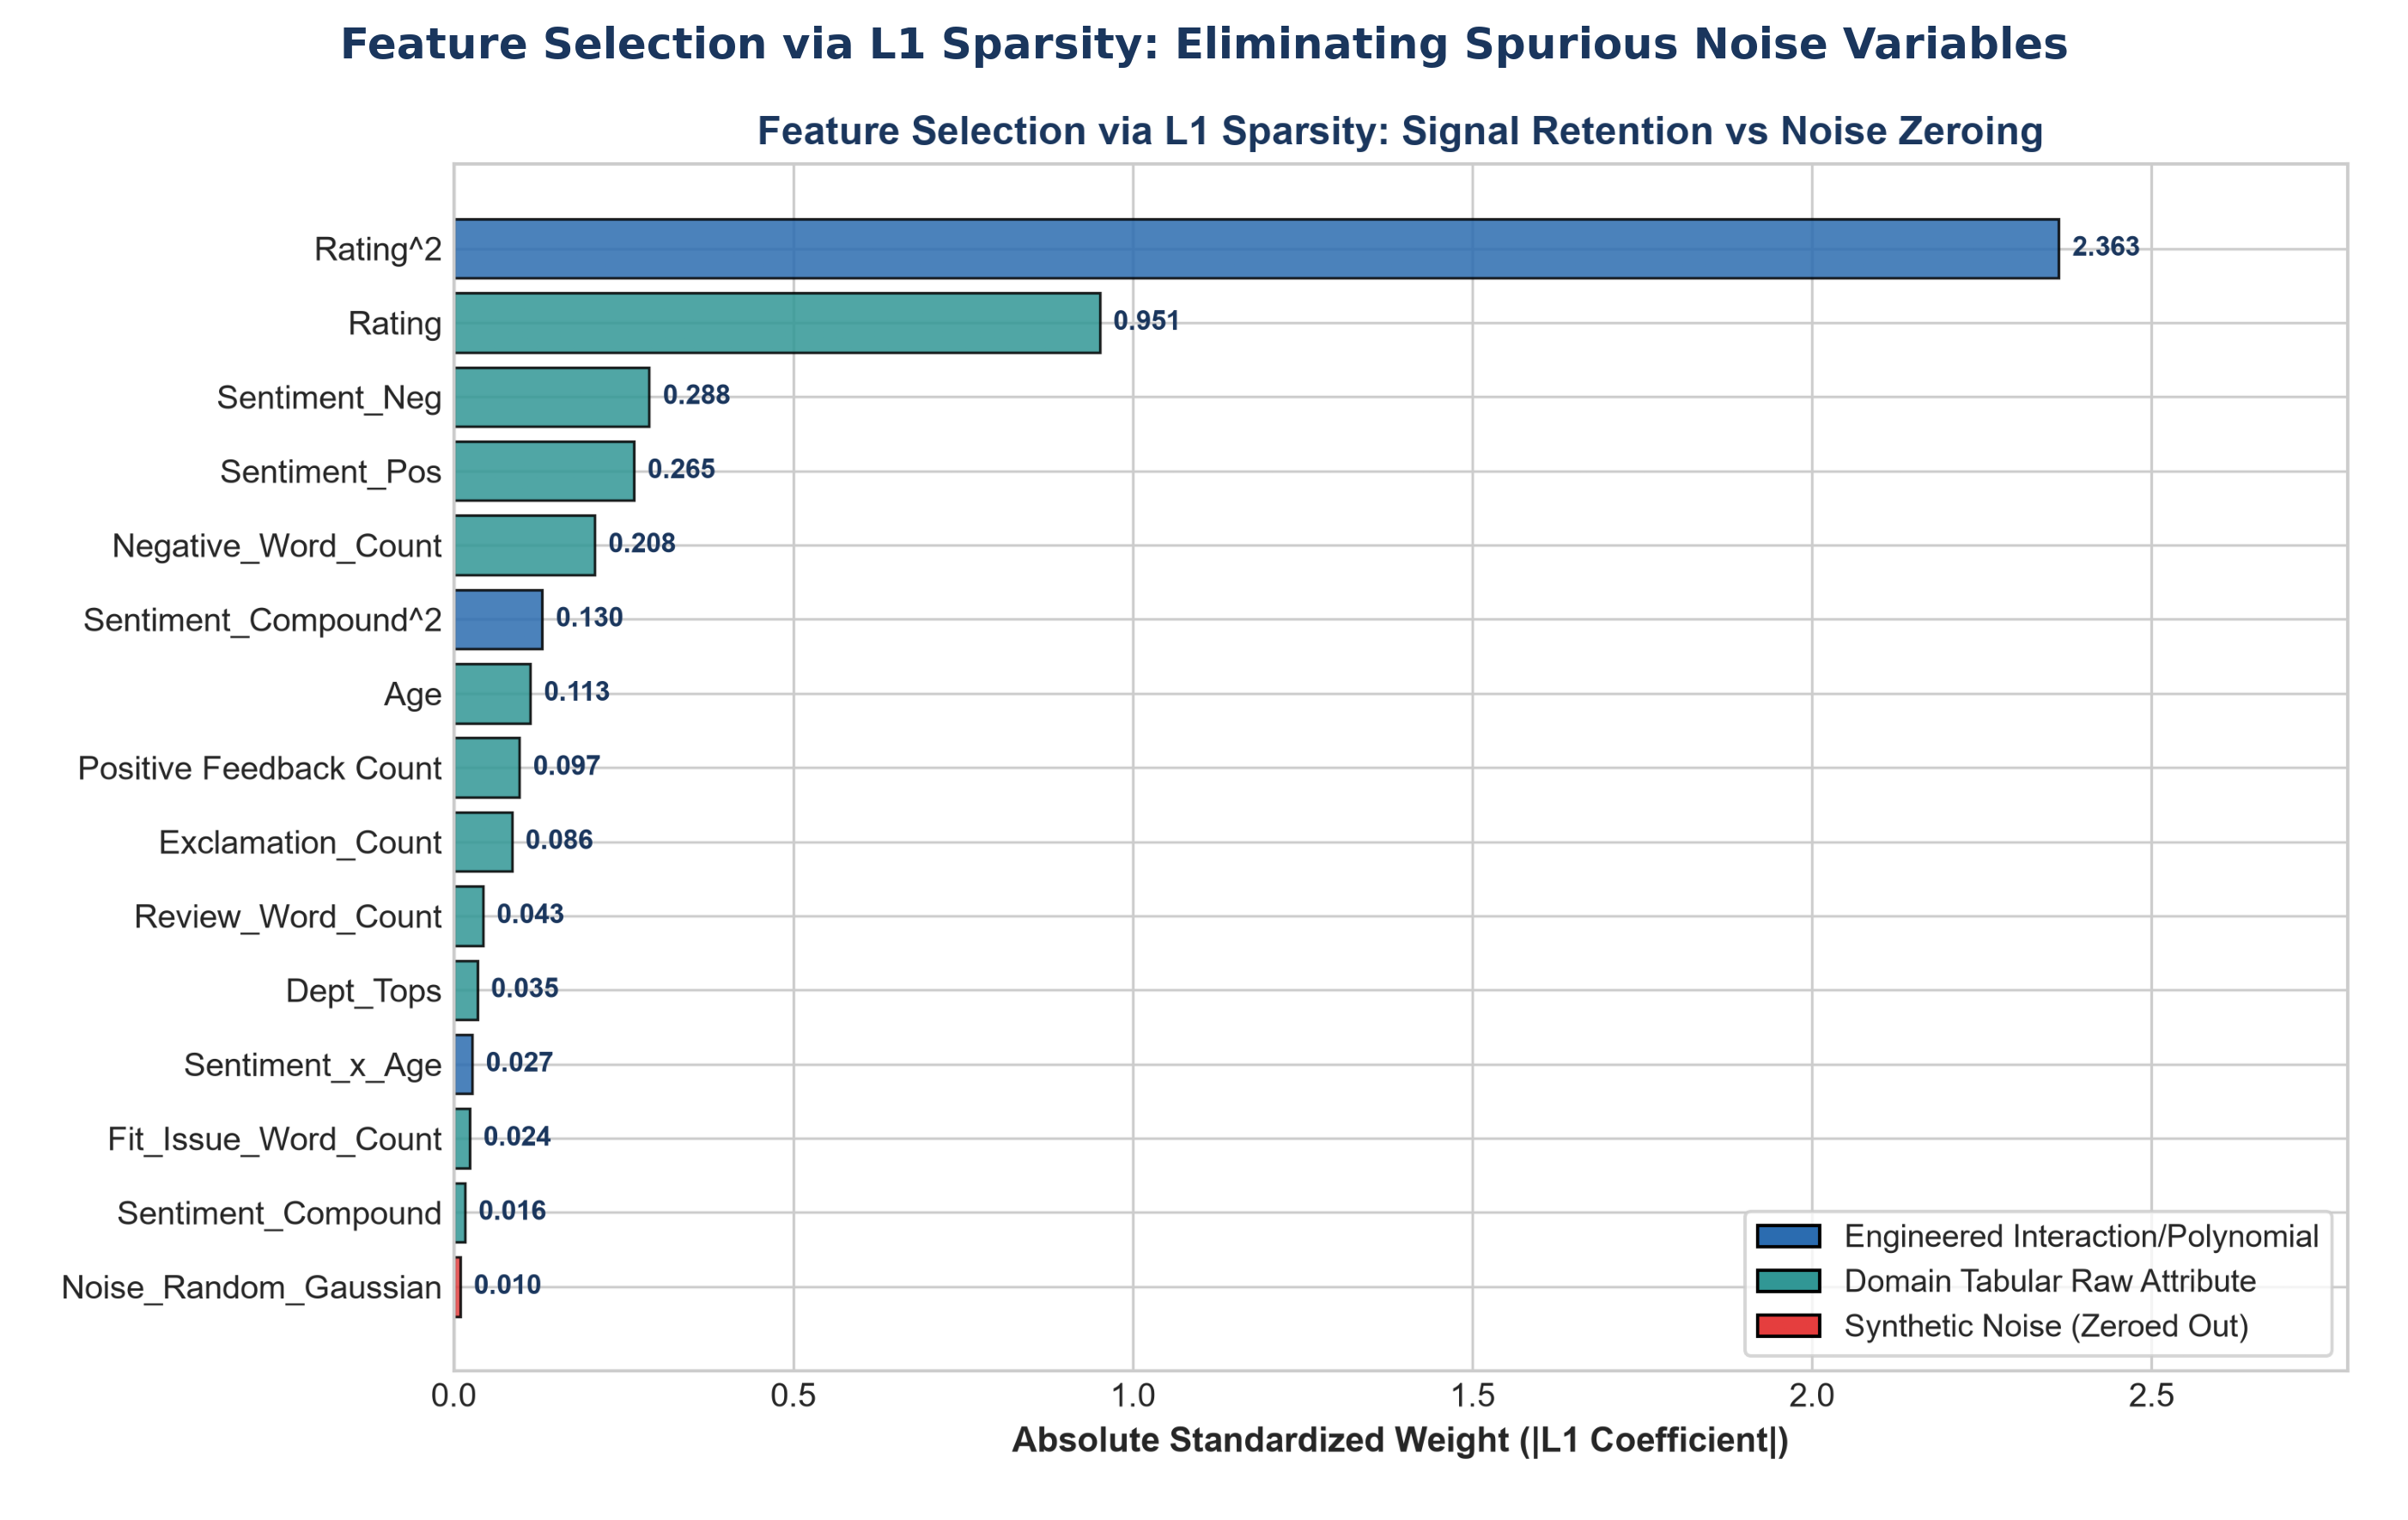

In [8]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
fs_img_path = "feature_selection_noise_removal_comparison.png"
if not os.path.exists(fs_img_path):
    fs_img_path = os.path.join("16-11-2026", "Task 2", "feature_selection_noise_removal_comparison.png")

img_fs = mpimg.imread(fs_img_path)
ax.imshow(img_fs)
ax.axis('off')
ax.set_title("Feature Selection via L1 Sparsity: Eliminating Spurious Noise Variables", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()


In [9]:
bench_csv = "regularization_and_ensemble_model_benchmarks.csv"
if not os.path.exists(bench_csv):
    bench_csv = os.path.join("16-11-2026", "Task 2", "regularization_and_ensemble_model_benchmarks.csv")

df_bench_table = pd.read_csv(bench_csv)
print("Comparative Model Benchmarks Across Regularization and Ensembling Paradigms:")
display(df_bench_table)


Comparative Model Benchmarks Across Regularization and Ensembling Paradigms:


,Model_Architecture,Regularization_Mechanism,Train_Accuracy,Test_Accuracy,Train_F1,Test_F1,Test_ROC_AUC,Generalization_Gap_Acc
0,Unregularized Baseline (Overfitted Tree),None (Full Variance),1.0000,0.9134,1.0000,0.9474,0.8488,0.0866
1,L1 Lasso Regularized Logistic Regression,L1 Sparsity (Lasso),0.9415,0.9425,0.9643,0.9650,0.9780,-0.0011
2,L2 Ridge Regularized Logistic Regression,L2 Shrinkage (Ridge),0.9419,0.9436,0.9646,0.9657,0.9779,-0.0017
3,Regularized Random Forest (Bagging),Tree Pruning & Bootstrap Aggregation,0.9439,0.9395,0.9656,0.9629,0.9758,0.0044
4,Regularized XGBoost (Boosting with L1/L2),Gradient Boosting + L1/L2 Leaf Regularization,0.9556,0.9402,0.9728,0.9635,0.9766,0.0154
5,Stacking Ensemble (Multi-Learner Generalization),Stacked Multi-Model Generalization,0.9469,0.9417,0.9677,0.9647,0.9771,0.0053


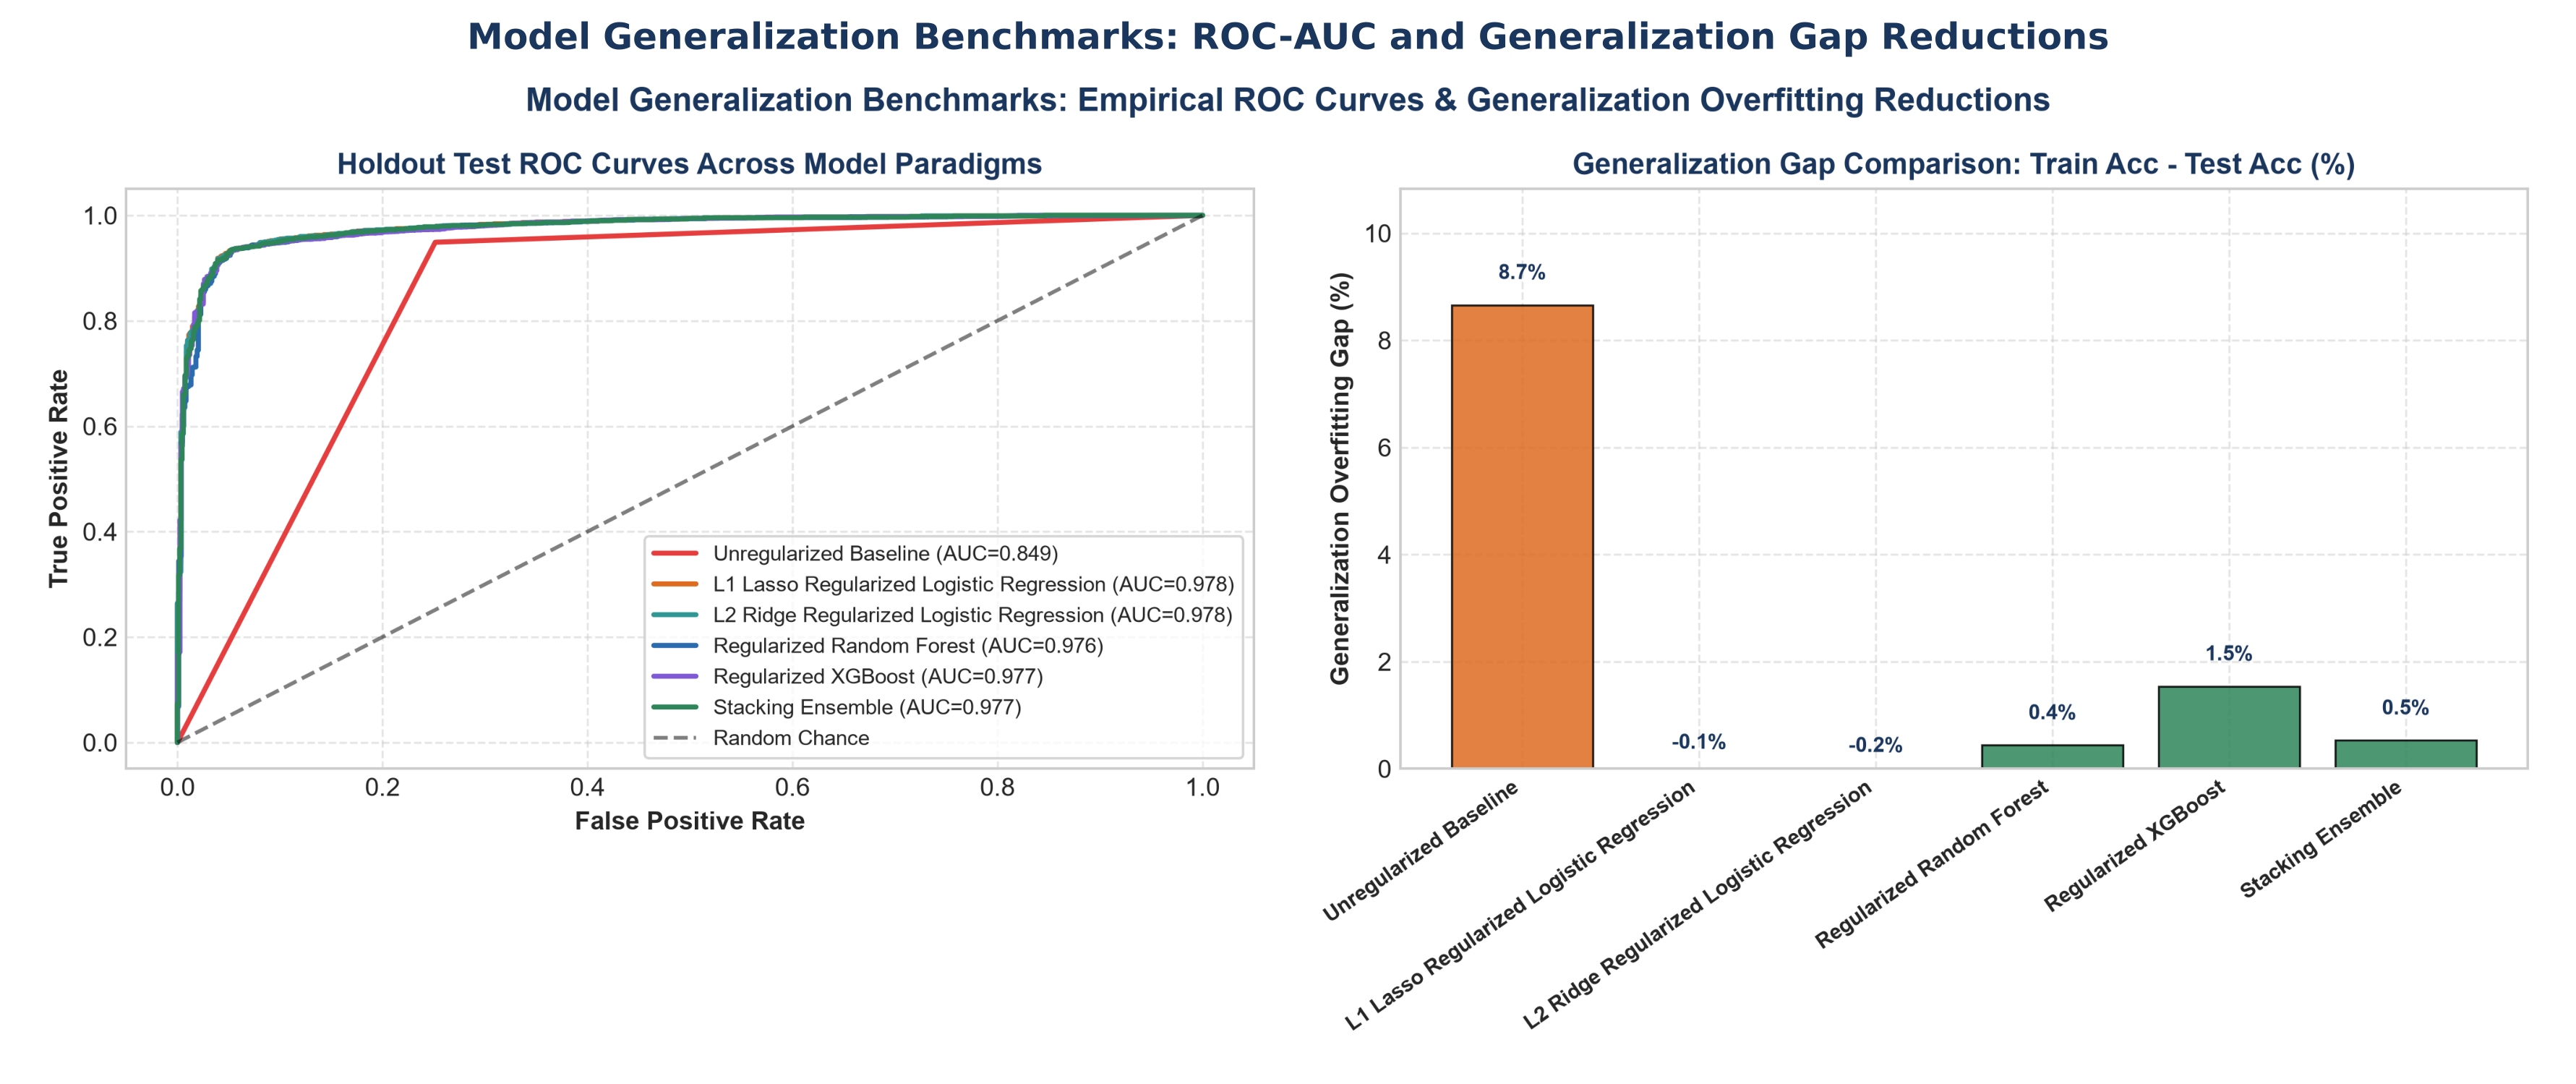

In [10]:
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
roc_img_path = "ensemble_generalization_and_roc_curves.png"
if not os.path.exists(roc_img_path):
    roc_img_path = os.path.join("16-11-2026", "Task 2", "ensemble_generalization_and_roc_curves.png")

img_roc = mpimg.imread(roc_img_path)
ax.imshow(img_roc)
ax.axis('off')
ax.set_title("Model Generalization Benchmarks: ROC-AUC and Generalization Gap Reductions", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()
